# BTC/USDT assistant for a first-time trader: research notebook

The assistant answers two questions:

1. **This week: how much of my BTC budget should I hold?** It runs five trend checks: is BTC higher than it was 1, 2, 4, 8 and 16 weeks ago?
2. **Today: if I buy now with a stop and a target, what usually happens in the next 24 hours?** This is the ML part: triple-barrier labels and a multinomial logistic regression.

Everything below runs from `src/` on Binance BTCUSDT 4h candles from January 2018 to June 2026. The data is in `data/`.
Splits are by time only: a purged, embargoed walk-forward from 2022 with quarterly refits, and the last 12 months kept as a test year.

`MODE = "placebo"` and `MODE = "control"` rerun everything on fake markets with no edge and with a small planted edge.

In [1]:
import json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
warnings.filterwarnings("ignore")
np.random.seed(0)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

MODE = "real"   # "real" | "placebo" | "control"
CSV = "data/btc_4h_data_2018_to_2025.csv"   # Binance 4h klines, Jan 2018 - Jun 2026 (in the repo)

## 1. Data
Binance spot klines include `taker_buy_base`, the volume bought by aggressive buyers. Funding comes from the USDT-margined perpetual (8-hourly). The last, still-forming bar is dropped.

cleaning report: {'rows_raw': 18512, 'duplicate_timestamp_rows': 4, 'outliers_dropped': 0, 'missing_bars': 16, 'missing_examples': ['2018-02-08 04:00:00+00:00', '2018-02-08 08:00:00+00:00', '2018-02-08 12:00:00+00:00', '2018-02-08 16:00:00+00:00', '2018-02-08 20:00:00+00:00'], 'rows_clean': 18510, 'first': '2018-01-01 00:00:00+00:00', 'last': '2026-06-15 12:00:00+00:00'}
18510 bars: 2018-01-01 00:00:00+00:00 -> 2026-06-15 12:00:00+00:00


,open_time,open,high,low,close,volume,taker_buy_base
18507,2026-06-15 04:00:00+00:00,"65,927.1100","66,000.0000","65,611.0100","65,674.7600","1,981.0906",965.9044
18508,2026-06-15 08:00:00+00:00,"65,674.7600","66,385.1200","65,512.0000","66,233.9000","2,545.8240","1,229.4630"
18509,2026-06-15 12:00:00+00:00,"66,233.8900","67,292.1500","66,106.0000","67,292.1400","5,314.3371","2,795.8789"


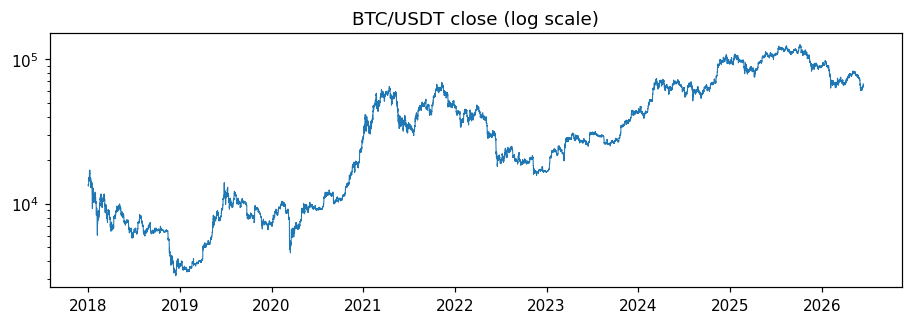

In [2]:
from src.data import load_market, make_synthetic
from src.data import load_binance_csv
if MODE == "real":
    report = {}
    kl, funding = load_binance_csv(CSV, report), None
    print("cleaning report:", report)
else:
    kl, funding = make_synthetic(edge=0.12 if MODE == "control" else 0.0)
print(len(kl), "bars:", kl.open_time.iat[0], "->", kl.open_time.iat[-1])
display(kl.tail(3))
fig, ax = plt.subplots(figsize=(10, 3)); ax.plot(kl.open_time, kl.close, lw=0.7); ax.set_yscale("log"); ax.set_title("BTC/USDT close (log scale)"); plt.show()

## 2. Target: triple-barrier trade outcome
Decision at the close of bar *t*, entry at the **open of t+1**. Target = entry*(1 + 1.5 sigma), stop = entry*(1 - 1.0 sigma), time limit 24h (6 bars). Sigma is an EWMA forecast of 24h volatility. It has no fitted parameters, so the labels are fixed before any model is trained. If one bar touches both barriers we count the **stop**.

We keep three outcomes (target / stop / time-out) instead of a binary label, because time-outs usually end near zero while stops lose a full unit of risk. Merging them would make good setups look bad.

In [3]:
from src.vol import ewma_sigma_24h
from src.labels import triple_barrier
sigma = ewma_sigma_24h(kl.close)
lab = triple_barrier(kl, sigma)
print(lab.outcome.value_counts(normalize=True).round(3))
R = lab.gross_ret / sigma
print("\nAverage result by outcome, in units of risk (R):"); print(R.groupby(lab.outcome).mean().round(2))

outcome
expiry   0.5930
stop     0.2730
target   0.1340
Name: proportion, dtype: float64

Average result by outcome, in units of risk (R):
outcome
expiry    0.1600
stop     -1.0000
target    1.5000
dtype: float64


### No-look-ahead tests
The features at *t* must not change when future bars are removed. The label at *t* must depend only on bars t+1 to t+6, and entry must be the next open.

In [4]:
import tests.test_no_lookahead as T
for name in [n for n in dir(T) if n.startswith("test_")]:
    getattr(T, name)(); print("PASS", name)

PASS test_entry_is_next_open
PASS test_features_do_not_use_future
PASS test_labels_only_use_bars_t_plus_1_to_t_plus_6
PASS test_sigma_does_not_use_future


## 3. Features
Eighteen causal features (funding is not in this dataset). Each one has a plain-English sentence, used for the "why" panel.

In [5]:
from src.features import FEATURE_DOCS
display(pd.DataFrame([(k, v[0], v[1]) for k, v in FEATURE_DOCS.items()], columns=["feature", "what it measures", "uses data from"]))

,feature,what it measures,uses data from
0,ret_1,"log return, last 4h",close[t]/close[t-1]
1,ret_6,"log return, last 24h",close[t]/close[t-6]
2,ret_24,"log return, last 4 days",close[t]/close[t-24]
3,ret_42,"log return, last 7 days",close[t]/close[t-42]
4,park_24,"Parkinson (high-low) volatility, 4 days",bars t-23..t
5,vol_ratio,short / long volatility (2d vs 14d),bars t-83..t
6,atr_pct,"average true range, % of price",bars t-13..t
7,dist_hi_7d,"distance to 7-day high, in ATRs",bars t-41..t
8,dist_lo_7d,"distance to 7-day low, in ATRs",bars t-41..t
9,dist_hi_30d,"distance to 30-day high, in ATRs",bars t-179..t


## 4. Run the full walk-forward
For each quarter from 2022 onward:
* Refit HAR-RV, the classifiers and the probability calibration on past data only.
* Purge any training row whose 24h label overlaps the fold, with a 6-bar embargo.

Models compared:
* **Base rate**: always predicts the historical outcome mix.
* **Multinomial logistic regression**: the primary model, chosen for interpretability.
* **Shallow GBM** (histogram, depth 3).

The GBM replaces the logistic model only under a rule written in advance: it must beat it on dev log-loss AND on dev net Sharpe.

In [6]:
from src.pipeline import run
o = run(synthetic=(MODE != "real"), control_edge=0.12 if MODE == "control" else 0.0, csv=CSV if MODE == "real" else None)
res = o["results"]
print("chosen model:", res["chosen_model"], "| edge validated on dev:", res["edge_validated"])

[data] 18510 bars 2018-01-01 00:00:00+00:00 -> 2026-06-15 12:00:00+00:00  synthetic=False
[vol] {'dev': {'qlike_har': 0.6775683568113897, 'qlike_ewma': 0.7352073585942962, 'rmse_har': 0.01472513266364131, 'rmse_ewma': 0.014567047824481783}, 'test': {'qlike_har': 0.5385073999791675, 'qlike_ewma': 0.553130897064408, 'rmse_har': 0.010813259678759572, 'rmse_ewma': 0.010341585243948485}}
[clf] {'base': (0.493, 0.9469), 'logreg': (0.612, 0.9268), 'gbm': (0.581, 0.9356), 'score': (0.508, 0.9482)}
chosen model: logreg | edge validated on dev: True


## 5. Does it predict? (out-of-sample)
*IC* is the Spearman correlation between the model's expected result and the realised net result for each bar.

In [7]:
rows = []
for m, v in res["clf"].items():
    for per, x in v.items():
        rows.append({"model": m, "period": per, **x})
display(pd.DataFrame(rows).set_index(["model", "period"]))
v = res["vol"]; print("Vol model QLIKE (lower = better):", {p: (round(x["qlike_har"], 4), round(x["qlike_ewma"], 4)) for p, x in v.items()}, "(HAR, EWMA)")

Vol model QLIKE (lower = better): {'dev': (0.6776, 0.7352), 'test': (0.5385, 0.5531)} (HAR, EWMA)


n  rate_stop  rate_timeout  rate_target  auc_target  auc_stop  logloss  brier  ic_expectedR
model  period                                                                                                
base   dev     7566     0.2702        0.5859       0.1439      0.4930    0.4658   0.9469 0.5636       -0.0522
       test    2188     0.3076        0.5631       0.1293      0.4798    0.5164   0.9542 0.5741       -0.0012
logreg dev     7566     0.2702        0.5859       0.1439      0.6121    0.5720   0.9268 0.5498        0.0301
       test    2188     0.3076        0.5631       0.1293      0.5127    0.6015   0.9476 0.5676        0.0712
gbm    dev     7566     0.2702        0.5859       0.1439      0.5806    0.5541   0.9356 0.5551        0.0022
       test    2188     0.3076        0.5631       0.1293      0.5446    0.5302   0.9562 0.5747        0.0013
score  dev     7566     0.2702        0.5859       0.1439      0.5083    0.5283   0.9482 0.5633       -0.0045
       test    2188     0.3076        0.5631       0.1293      0.4765    0.5452   0.9541 0.5732        0.0133

## 5b. Simplicity test: does a 5-rule points card lose anything?
Following Ustun & Rudin (2019) and Hand (2006): the default model is a scorecard of at most 5 yes/no rules with integer points.
The logistic model and the GBM replace it only if they beat it on dev rank-IC (by > 0.02) **and** on dev net Sharpe.

In [8]:
display(pd.DataFrame(res["simplicity_test"]).T)
print("chosen:", res["chosen_model"])
print("Current scorecard:"); display(pd.DataFrame(res["scorecard_latest"]))

chosen: logreg
Current scorecard:


,n_inputs,dev_auc,test_auc,dev_ic,test_ic,dev_sharpe,test_sharpe
score,<= 5 yes/no rules,0.5083,0.4765,-0.0045,0.0133,-0.7252,0.0000
logreg,18 features,0.6121,0.5127,0.0301,0.0712,0.7102,-1.8317
gbm,"18 features, trees",0.5806,0.5446,0.0022,0.0013,0.1076,0.0000


,rule,points,text
0,park_24|high,-3,The market has been unusually jumpy
1,dist_hi_30d|high,3,Price is close to its 30-day high
2,ret_24|low,-3,Price is down over the last few days
3,px_vs_ema|high,2,Price is stretched above its 8-day average
4,dist_hi_7d|low,-1,Price is well below its 7-day high


## 6. Backtest, net of 0.10% fee + 0.03% slippage per side
One position at a time, long-only spot. Baselines: **always take the trade** (this isolates whether the model's filter adds value) and **buy and hold**.

In [9]:
bt = pd.DataFrame(res["backtests"]).T
display(bt[["n_trades", "win_rate", "stop_rate", "avg_R", "cagr", "sharpe", "max_dd", "exposure"]])
print("Deflated Sharpe (dev):", res["deflated_sharpe_dev"])
display(pd.DataFrame({k: {"model_sharpe": v["model"]["sharpe"], "model_cagr": v["model"]["cagr"],
                           "always_sharpe": v["always_take"]["sharpe"]} for k, v in res["cost_sensitivity_test"].items()}).T.rename_axis("cost x"))

Deflated Sharpe (dev): {'n_trials': 8, 'sr_daily': 0.037172616564602586, 'sr0_daily': 0.03192196630152768, 'dsr': 0.5754606193118827}


,n_trades,win_rate,stop_rate,avg_R,cagr,sharpe,max_dd,exposure
score|all_signals|dev,59.0000,0.0847,0.2712,-0.1571,-0.0828,-0.7252,-0.2945,0.0397
score|all_signals|test,0.0000,NaN,NaN,NaN,0.0000,0.0000,0.0000,0.0000
score|medium_plus|dev,0.0000,NaN,NaN,NaN,0.0000,0.0000,0.0000,0.0000
score|medium_plus|test,0.0000,NaN,NaN,NaN,0.0000,0.0000,0.0000,0.0000
logreg|all_signals|dev,182.0000,0.2088,0.2143,0.1018,0.1157,0.7102,-0.1970,0.1179
logreg|all_signals|test,5.0000,0.0000,0.6000,-0.6800,-0.0690,-1.8317,-0.0786,0.0100
logreg|medium_plus|dev,78.0000,0.2179,0.2564,0.0487,0.0087,0.1335,-0.1553,0.0481
logreg|medium_plus|test,0.0000,NaN,NaN,NaN,0.0000,0.0000,0.0000,0.0000
gbm|all_signals|dev,69.0000,0.1594,0.2174,0.0205,0.0058,0.1076,-0.1677,0.0459
gbm|all_signals|test,0.0000,NaN,NaN,NaN,0.0000,0.0000,0.0000,0.0000


,model_sharpe,model_cagr,always_sharpe
cost x,,,
0.0,-1.6486,-0.0568,-0.7715
1.0,-1.8317,-0.0690,-3.7910
2.0,-1.9649,-0.0811,-6.6881


## 7. Robustness and honest track record

In [10]:
rob = res["robustness"]
display(pd.DataFrame({k: {"auc_target": v["clf"]["auc_target"], "ic": v["clf"]["ic_expectedR"],
                           "model_trades": v["model"]["n_trades"], "model_sharpe": v["model"]["sharpe"],
                           "always_sharpe": v["always_take"]["sharpe"]} for k, v in rob.items() if k.startswith("barriers")}).T)
print("Drop top feature:", rob["drop_top_feature"]["feature"], {p: round(rob["drop_top_feature"][p]["auc_target"], 3) for p in ("dev", "test")})
display(pd.DataFrame(rob["by_year"]).T[["auc_target", "ic_expectedR", "coverage", "signal_avg_net_R"]])
display(pd.DataFrame(rob["by_regime"]).T[["n", "auc_target", "ic_expectedR"]])
display(pd.DataFrame({k: v for k, v in res["track_record_test"].items() if isinstance(v, dict)}).T)
print("Logistic weights (target vs stop):", list(res["coef_target_vs_stop_dev"].items())[:8])

Drop top feature: px_vs_ema {'dev': 0.612, 'test': 0.505}
Logistic weights (target vs stop): [('px_vs_ema', 0.9107), ('ema_slope', -0.3545), ('park_24', -0.3178), ('ret_6', -0.2418), ('atr_pct', 0.1634), ('ret_24', -0.1177), ('ret_42', -0.1109), ('taker', 0.0773)]


,auc_target,ic,model_trades,model_sharpe,always_sharpe
barriers_x0.75|dev,0.5724,0.0226,96.0000,-0.1822,-2.7158
barriers_x0.75|test,0.5081,0.0783,1.0000,-0.9986,-4.2514
barriers_x1.25|dev,0.6407,0.0253,212.0000,0.1971,-1.8005
barriers_x1.25|test,0.5106,0.0739,13.0000,-0.8471,-3.1676


,auc_target,ic_expectedR,coverage,signal_avg_net_R
2022,0.6259,-0.0655,0.0023,0.8014
2023,0.5979,0.0226,0.0420,0.0453
2024,0.5971,0.0136,0.1931,0.0487
2025,0.5580,0.0097,0.0416,-0.0417
2026,0.5505,0.1411,0.0071,-0.7610


,n,auc_target,ic_expectedR
calm,"5,201.0000",0.5855,0.0618
normal,"4,526.0000",0.5672,0.0133


,n_bars,target_rate,stop_rate,avg_net_R,avg_predicted_R
Low,10.0000,0.0000,0.4000,-0.4700,0.0695
Medium,0.0000,NaN,NaN,NaN,NaN
High,0.0000,NaN,NaN,NaN,NaN


## 7b. Is it luck?
Random entries with the same trade count, a circular-shift test on the ranking, profit by year, and how often one candle touched both levels.

In [11]:
from src.analysis import run_all_checks
checks = run_all_checks(o, CSV.replace("4h", "1h") if MODE == "real" else None)
res["luck_checks"] = checks
print(json.dumps({k: v for k, v in checks.items() if k not in ("by_year_trades", "release_gate", "sized_short_term")}, indent=1))
display(pd.DataFrame(checks["by_year_trades"]).T)
print("Release gate for the short-term buy signal (development period only):")
print(json.dumps(checks["release_gate"], indent=1))
print("Short-term strategy with the card's 1%-risk sizing:")
display(pd.DataFrame(checks["sized_short_term"]).T)

{
 "random_entry_dev": {
  "n_trades": 182,
  "model_sharpe": 0.7101818422942977,
  "model_total_return": 0.4588783823894391,
  "random_sharpe_median": -0.9262392304403417,
  "random_total_return_median": -0.47111148680184517,
  "p_value_sharpe": 0.0,
  "p_value_return": 0.0,
  "n_sims": 500
 },
 "random_entry_test": {
  "n_trades": 5,
  "model_sharpe": -1.8317342042586242,
  "model_total_return": -0.06897503636529123,
  "random_sharpe_median": -0.3185569194072311,
  "random_total_return_median": -0.009989900003861851,
  "p_value_sharpe": 0.926,
  "p_value_return": 0.96,
  "n_sims": 500
 },
 "ic_shift_dev": {
  "ic": 0.030102639920798365,
  "p_value": 0.126,
  "null_95pct": 0.04105117255199396,
  "n": 7566
 },
 "ic_shift_test": {
  "ic": 0.07119331440167326,
  "p_value": 0.022,
  "null_95pct": 0.05573441070796475,
  "n": 2188
 },
 "same_bar": {
  "labels": 18396,
  "ambiguous": 7,
  "ambiguous_share": 0.000380517503805175,
  "would_flip_to_target_with_1h": 2
 }
}
Release gate for the s

,trades,net_return,target,stop,timeout
2022,3.0000,0.1213,2.0000,0.0000,1.0000
2023,32.0000,0.0700,8.0000,7.0000,17.0000
2024,117.0000,0.3169,22.0000,24.0000,71.0000
2025,33.0000,-0.1044,6.0000,10.0000,17.0000
2026,2.0000,-0.0402,0.0000,1.0000,1.0000


,total_return,cagr,sharpe,max_dd,exposure,n_trades,trades_per_month,win_rate,stop_rate,avg_net_trade,avg_R,avg_weight_in_trade
dev,0.1721,0.0471,0.7996,-0.0690,0.1179,182.0000,4.3965,0.2088,0.2143,0.0023,0.1018,0.3632
test,-0.0299,-0.0300,-1.7502,-0.0345,0.0100,5.0000,0.4170,0.0000,0.6000,-0.0141,-0.6800,0.4321


## 7c. The big picture: a trend gauge (time-series momentum)
Five checks every Sunday: is BTC higher than 1, 2, 4, 8 and 16 weeks ago? Each yes = hold one fifth of the BTC budget.
Nothing is fitted (equal weights). I added this after seeing the 24h model's test year, so I also check 2018-2021, which was never used for any decision, and I report every variant.

In [12]:
from src.momentum import full_study
trend, d_daily, W = full_study(o["df"], o["end"])
res["trend"] = trend
o["trend_daily"], o["trend_W"] = d_daily, W
for m in ["total_return", "cagr", "sharpe", "max_dd", "avg_weight"]:
    print(m); display(pd.DataFrame({v: {p: s[m] for p, s in per.items()} for v, per in trend["variants"].items()}).T.round(3))
print("Sharpe difference vs buy and hold (weekly trend), block bootstrap:")
display(pd.DataFrame(trend["bootstrap_vs_buy_hold"]["trend_weekly"]).T)
print("Deflated Sharpe (full period):", round(trend["deflated_sharpe_full"]["trend_weekly"]["dsr"], 3),
      "| position changes per year:", round(trend["weekly_changes_per_year"], 1))

total_return
cagr
sharpe
max_dd
avg_weight
Sharpe difference vs buy and hold (weekly trend), block bootstrap:
Deflated Sharpe (full period): 0.989 | position changes per year: 36.7


,early_2018_2021,dev_2022_2025,test_2025_2026,full_2018_2026
buy_hold,5.1750,1.2810,-0.3760,7.7840
trend_daily,6.6900,1.1590,-0.1060,13.8350
trend_weekly,7.4890,1.0910,-0.1500,14.0810
trend_daily_volscaled,4.4370,1.1460,-0.0970,9.5350
trend_7d_only,3.2900,-0.0340,-0.1740,2.4240
trend_14d_only,6.3940,1.2210,-0.0110,15.2400
trend_28d_only,8.3590,1.2920,-0.0930,18.4510
trend_56d_only,9.5750,1.6740,-0.1830,22.1160
trend_112d_only,3.8050,1.5400,-0.1290,9.6310


,early_2018_2021,dev_2022_2025,test_2025_2026,full_2018_2026
buy_hold,0.6620,0.2700,-0.3770,0.3110
trend_daily,0.7670,0.2500,-0.1070,0.3990
trend_weekly,0.8160,0.2380,-0.1510,0.4020
trend_daily_volscaled,0.6040,0.2480,-0.0970,0.3400
trend_7d_only,0.5010,-0.0100,-0.1740,0.1660
trend_14d_only,0.7480,0.2600,-0.0110,0.4150
trend_28d_only,0.8660,0.2720,-0.0940,0.4470
trend_56d_only,0.9310,0.3300,-0.1830,0.4780
trend_112d_only,0.5500,0.3100,-0.1290,0.3420


,early_2018_2021,dev_2022_2025,test_2025_2026,full_2018_2026
buy_hold,1.0660,0.7130,-0.8870,0.7500
trend_daily,1.4230,0.8760,-0.5010,1.0620
trend_weekly,1.4750,0.8250,-0.7470,1.0570
trend_daily_volscaled,1.4780,0.9100,-0.4550,1.0870
trend_7d_only,1.0350,0.1430,-0.6520,0.5700
trend_14d_only,1.3350,0.8180,0.0720,1.0230
trend_28d_only,1.4380,0.8350,-0.2970,1.0620
trend_56d_only,1.4840,0.9880,-0.7700,1.1130
trend_112d_only,1.0670,0.9390,-0.5430,0.8850


,early_2018_2021,dev_2022_2025,test_2025_2026,full_2018_2026
buy_hold,-0.6340,-0.6690,-0.5120,-0.7660
trend_daily,-0.3840,-0.3430,-0.2130,-0.4820
trend_weekly,-0.4030,-0.3380,-0.2510,-0.4700
trend_daily_volscaled,-0.3320,-0.3180,-0.2050,-0.4430
trend_7d_only,-0.4450,-0.5200,-0.3430,-0.6920
trend_14d_only,-0.4950,-0.4690,-0.1930,-0.5280
trend_28d_only,-0.5610,-0.4080,-0.2270,-0.5610
trend_56d_only,-0.4400,-0.4450,-0.3010,-0.4450
trend_112d_only,-0.5780,-0.2760,-0.2630,-0.6000


,early_2018_2021,dev_2022_2025,test_2025_2026,full_2018_2026
buy_hold,1.0000,1.0000,1.0000,1.0000
trend_daily,0.5690,0.5360,0.4440,0.5390
trend_weekly,0.5670,0.5300,0.4350,0.5350
trend_daily_volscaled,0.4430,0.4970,0.4400,0.4660
trend_7d_only,0.5530,0.5250,0.4670,0.5300
trend_14d_only,0.5560,0.5410,0.4670,0.5380
trend_28d_only,0.5660,0.5450,0.4560,0.5430
trend_56d_only,0.5860,0.5340,0.4430,0.5460
trend_112d_only,0.5830,0.5330,0.3880,0.5370


,sharpe_a,sharpe_b,diff,ci95,p_value_diff_le_0
early_2018_2021,1.4754,1.0661,0.4093,"[-0.20763835636745007, 1.0148383021236715]",0.0905
dev_2022_2025,0.8258,0.7135,0.1123,"[-0.49170346572227736, 0.7261504427121269]",0.3880
test_2025_2026,-0.7477,-0.8887,0.1409,"[-1.0040166327129931, 1.3009780269295712]",0.4435
full_2018_2026,1.0573,0.7500,0.3073,"[-0.09248085591704255, 0.695820466194114]",0.0710


## 8. Figures, results appendix and the trader dashboard

short-term mode: research | open outputs/dashboard.html


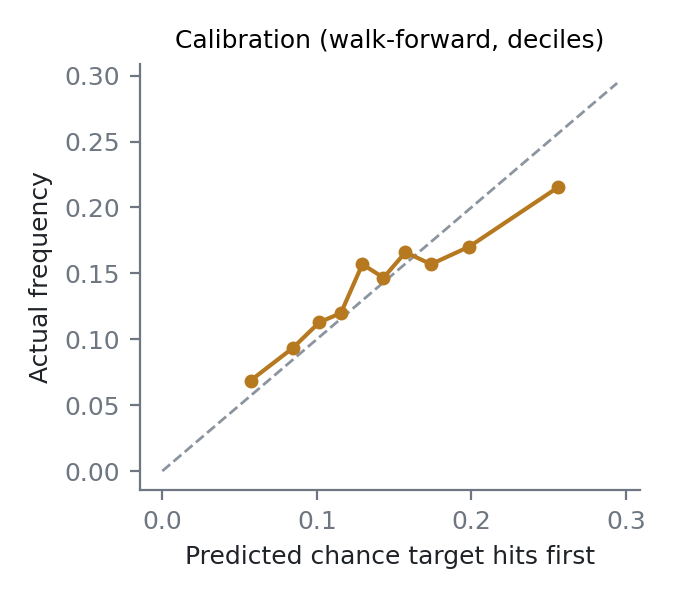

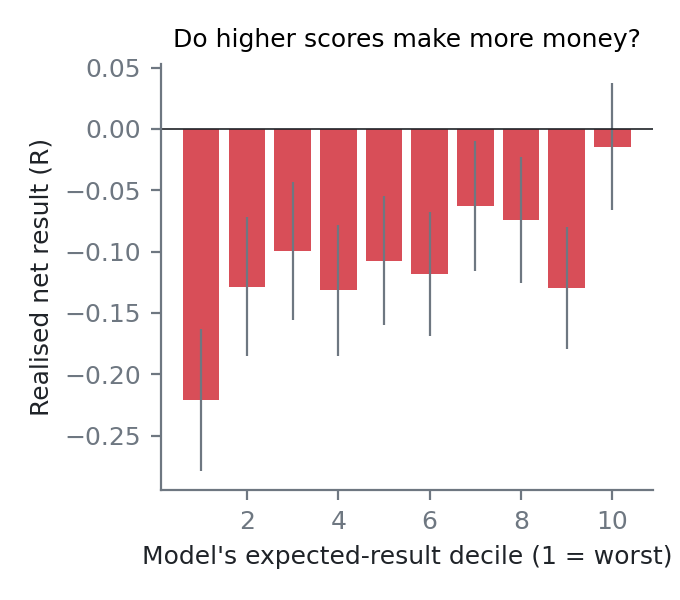

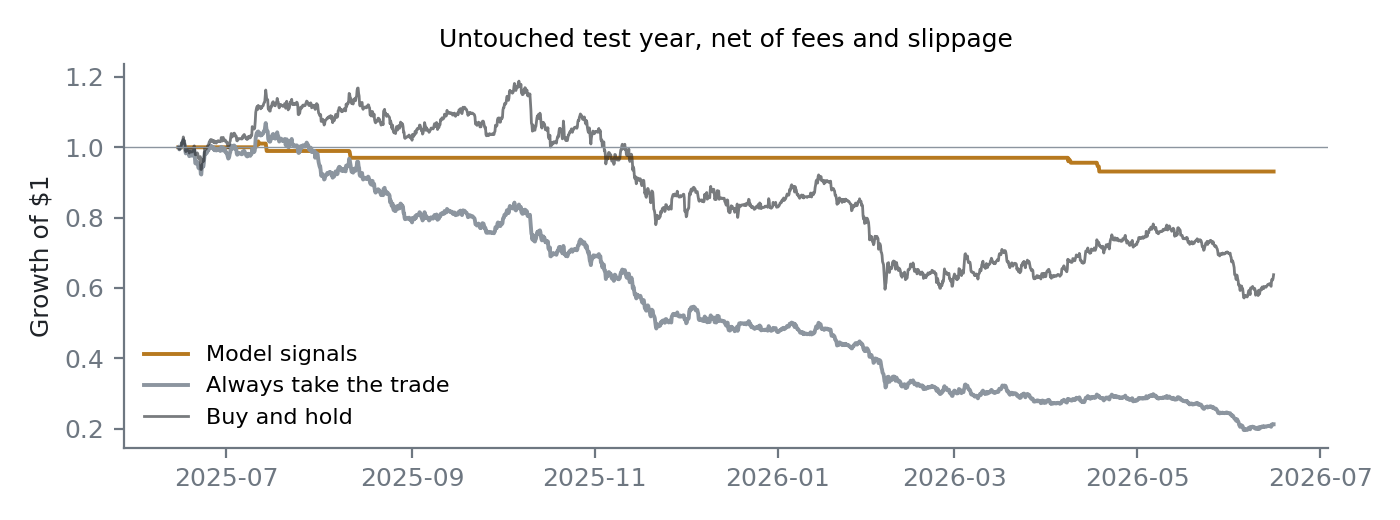

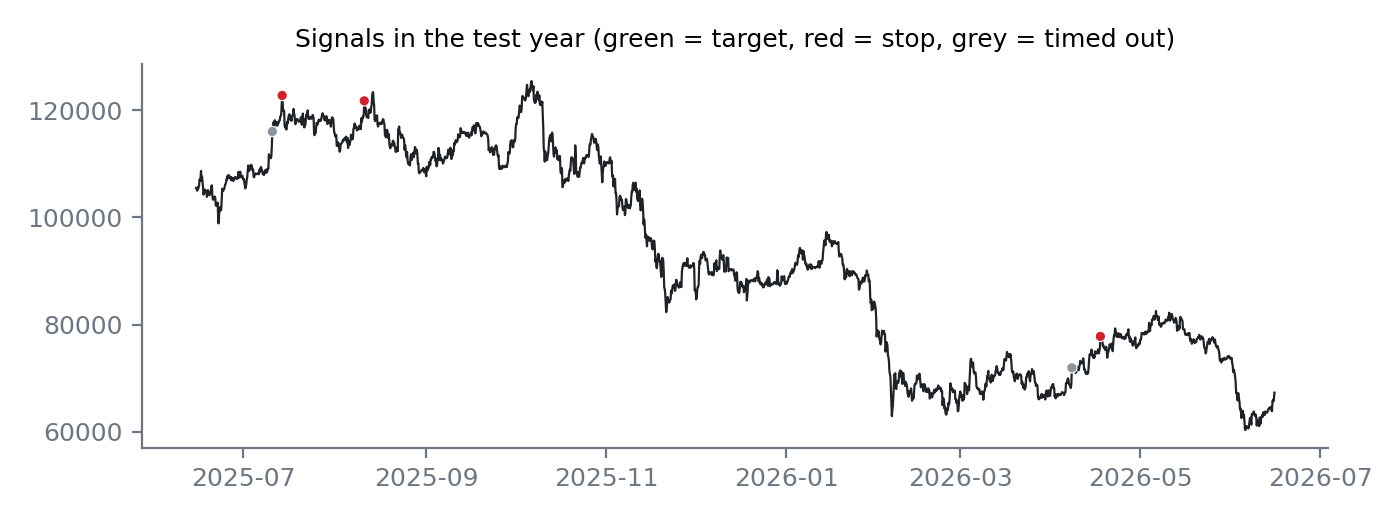

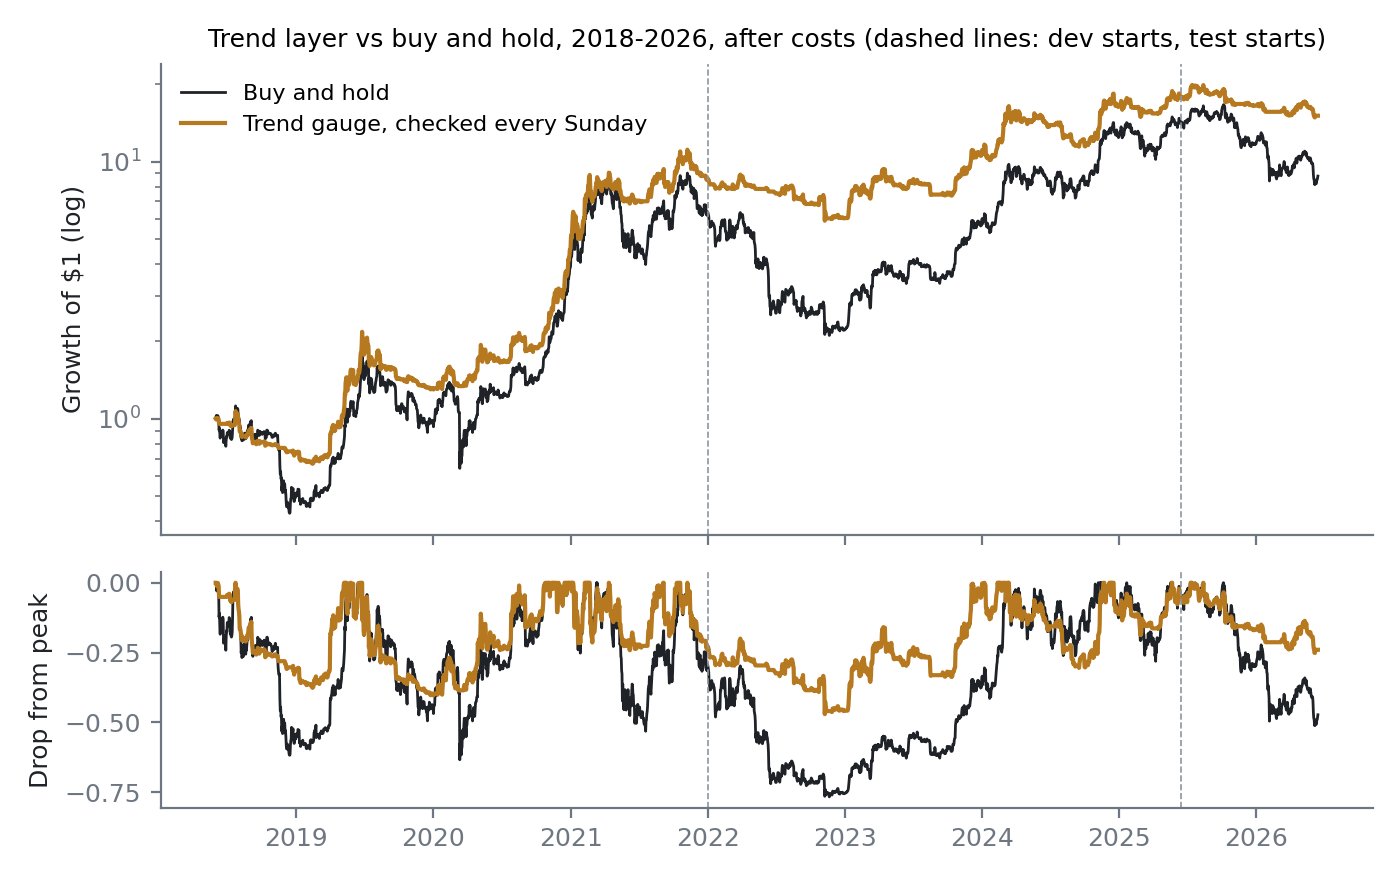

In [13]:
from pathlib import Path
from src.report import figures, results_pdf, dashboard
from src.momentum import gauge_at
out = Path({"real": "outputs", "placebo": "outputs_placebo", "control": "outputs_control"}[MODE]); out.mkdir(exist_ok=True)
gate = res["luck_checks"]["release_gate"]["passed"]
res["short_term_mode"] = "live" if gate else "research"
for c in o["cards"]:
    c["trend"] = gauge_at(o["trend_W"]["trend_weekly"], o["trend_daily"], c["time"])
    c["short_term_mode"] = res["short_term_mode"]
    if not gate and c.get("data_ok", True) and c["trade"]:
        c["headline"] = "Model leans up, but it has not passed the release test \u2014 no buy signal"
files = figures(o, out / "figures")
for f in files.values(): display(Image(filename=str(f), width=640))
results_pdf(o, files, out / "results_appendix.pdf"); dashboard(o, out / "dashboard.html")
(out / "results.json").write_text(json.dumps(res, indent=1, default=str))
print("short-term mode:", res["short_term_mode"], "| open", out / "dashboard.html")

## 9. The latest card (what a new trader sees)

In [14]:
print(json.dumps(res["latest_card"], indent=1))

{
 "time": "2026-06-15 16:00",
 "price": 67292.14,
 "headline": "No clear edge \u2014 stay out",
 "data_ok": true,
 "confidence": "None",
 "trade": false,
 "regime": "normal",
 "p_target": 0.184,
 "p_stop": 0.299,
 "p_timeout": 0.517,
 "win_share": 0.381,
 "win_share_needed": 0.441,
 "expected_R": -0.046,
 "entry": 67292.14,
 "stop": 65598.39,
 "target": 69832.77,
 "stop_pct": 2.52,
 "target_pct": 3.78,
 "size_for_1pct_risk_on_1000": 360.1,
 "loss_if_stop": 10.0,
 "gain_if_target": 12.66,
 "expires": "2026-06-15 20:00",
 "expected_range_pct": 2.89,
 "reasons": [
  {
   "text": "Price is stretched above its 8-day average",
   "direction": "supports buying"
  },
  {
   "text": "Price is up over the last day",
   "direction": "argues against buying"
  },
  {
   "text": "The 8-day trend is pointing up",
   "direction": "argues against buying"
  }
 ],
 "score": null,
 "of10": [
  2,
  5,
  3
 ],
 "dollars_per_10_risked": -0.46,
 "education": "Risking 1% of your account per trade means ten l